In [18]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import shap
import os
import joblib
from sklearn.model_selection import train_test_split
from pathlib import Path

from utils_benchmark import load_and_prepare_data
from config import RANDOM_STATE

shap.initjs()

In [19]:
base_csv = "data/survey/data-base.csv"
personnes_csv = "data/survey/data-personnes.csv"
photos_csv = "data/survey/data-photos.csv"
model_filepath = Path(f"outputs/photo_people/model_results/models/")
shap_filepath = Path(f"outputs/photo_people/model_results/shap_values/")

In [20]:
X,y = load_and_prepare_data(base_csv, personnes_csv, photos_csv, people=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

In [21]:
model_name = "gradient_boost"
model = joblib.load(f"{model_filepath}/{model_name}.joblib")

/opt/miniconda3/envs/env6/lib/python3.14/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator DummyClassifier from version 1.9.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/opt/miniconda3/envs/env6/lib/python3.14/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator DecisionTreeRegressor from version 1.9.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/opt/miniconda3/envs/env6/lib/python3.14/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator GradientBoostingClassifier from version 1.9

In [22]:
explainer = shap.Explainer(model.predict_proba, X_train)
shap_values = explainer(X_test)

In [23]:
class_id = 0
print(f"Note : {class_id}")
shap.plots.force(shap_values[0, :, class_id])

In [24]:
class_id = 1
print(f"Note : {class_id}")
shap.plots.force(shap_values[0, :, class_id])

In [25]:
class_id = 2
print(f"Note : {class_id}")
shap.plots.force(shap_values[0, :, class_id])

In [26]:
class_id = 3
print(f"Note : {class_id}")
shap.plots.force(shap_values[0, :, class_id])

In [27]:
class_id = 4
print(f"Note : {class_id}")
shap.plots.force(shap_values[0, :, class_id])

In [28]:
shap.plots.force(shap_values[..., 0])

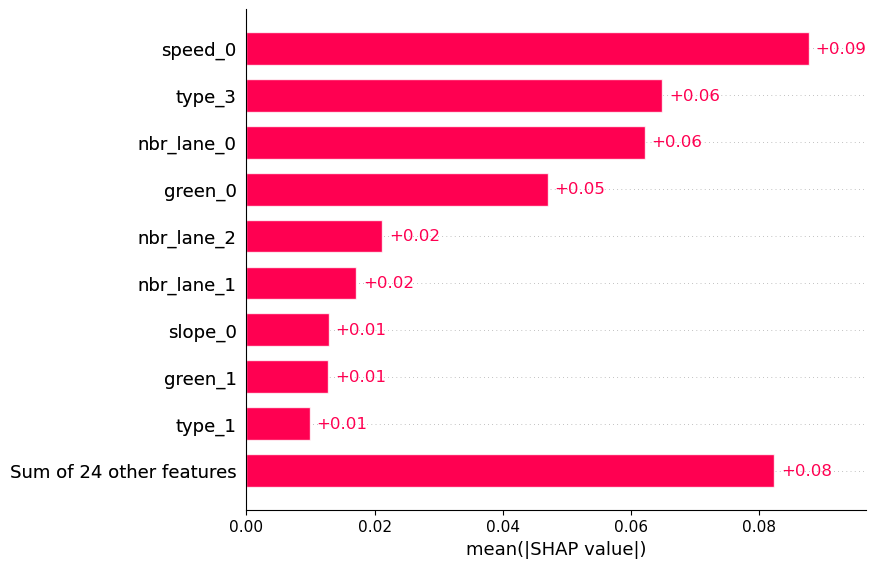

In [38]:
shap.plots.bar(shap_values[..., 4])

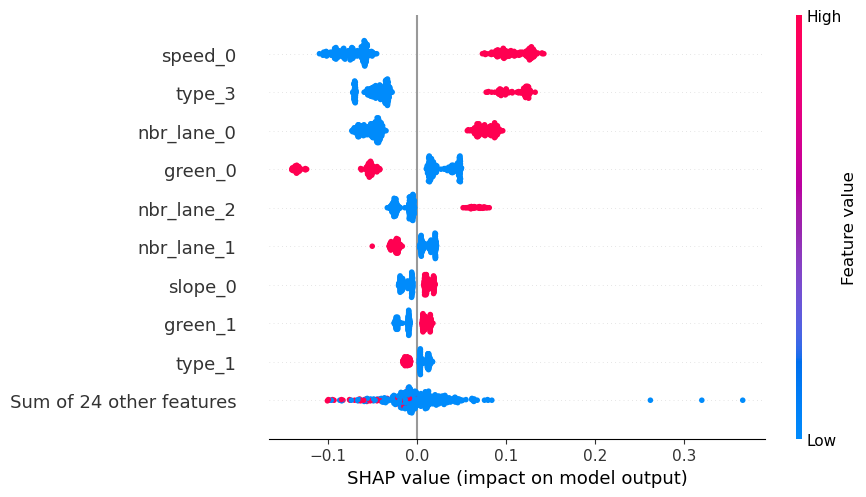

In [35]:
shap.plots.beeswarm(shap_values[..., 4])

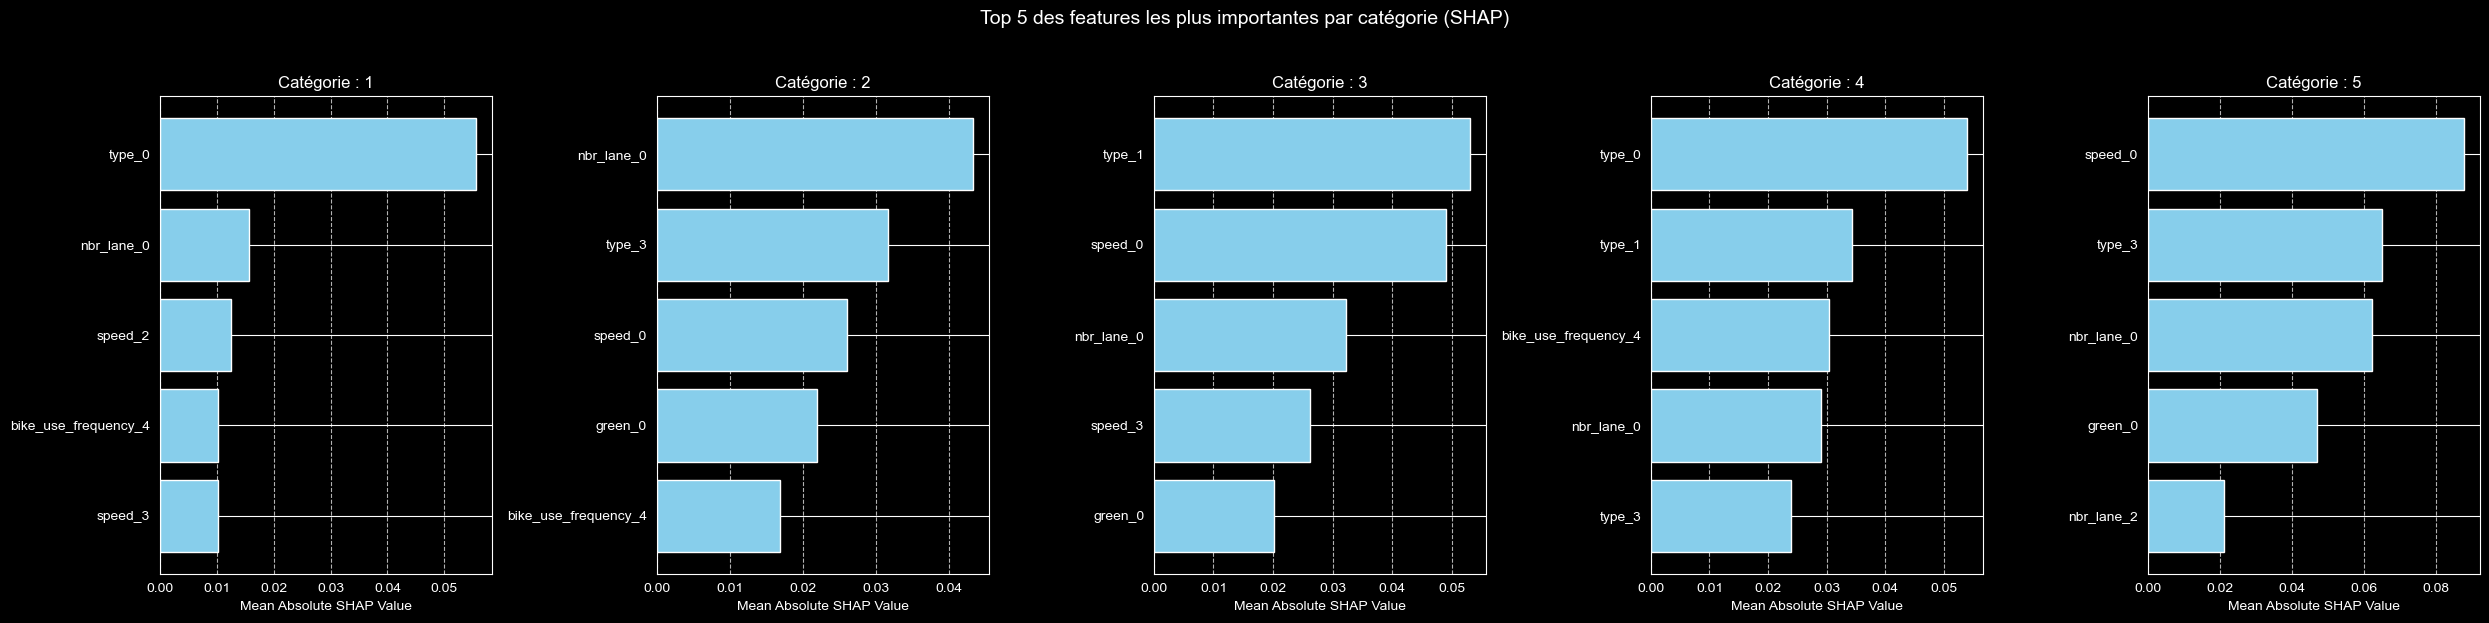

In [41]:
class_names = getattr(model, "classes_", [f"Classe {i}" for i in range(len(shap_values))])
feature_names = X_test.columns.tolist()

# 2. Uniformisation du format des valeurs SHAP pour gérer les listes ou les tableaux 3D
if isinstance(shap_values, shap.Explanation):
    # Format moderne Explanation : shape (n_samples, n_features, n_classes)
    values = shap_values.values
elif isinstance(shap_values, list):
    # Liste de tableaux de shape (n_samples, n_features) pour chaque classe
    values = np.array(shap_values)  # shape (n_classes, n_samples, n_features)
    values = np.transpose(values, (1, 2, 0))  # Passage à (n_samples, n_features, n_classes)
else:
    values = shap_values

n_classes = values.shape[2]

# 3. Création des subplots (un bar plot par catégorie)
fig, axes = plt.subplots(1, n_classes, figsize=(5 * n_classes, 6), sharex=False)
if n_classes == 1:
    axes = [axes]

for i, class_name in enumerate(class_names):
    ax = axes[i]

    # Calcul de la moyenne des valeurs absolues SHAP pour la classe i
    mean_abs_shap = np.mean(np.abs(values[:, :, i]), axis=0)

    # DataFrame pour trier les features
    df_importance = pd.DataFrame({
        "feature": feature_names,
        "mean_abs_shap": mean_abs_shap
    })

    # Sélection des 5 features les plus importantes (triées pour affichage horizontal)
    df_top5 = df_importance.sort_values(by="mean_abs_shap", ascending=True).tail(5)

    # Tracé du bar plot horizontal
    ax.barh(df_top5["feature"], df_top5["mean_abs_shap"], color="skyblue")
    ax.set_title(f"Catégorie : {int(class_name)+1}")
    ax.set_xlabel("Mean Absolute SHAP Value")
    ax.grid(axis="x", linestyle="--", alpha=0.7)

plt.suptitle("Top 5 des features les plus importantes par catégorie (SHAP)", fontsize=14, y=1.03)
plt.tight_layout()
plt.show()